In [34]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import KNNImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 200)
SEED = 42

In [35]:
DATA_PATH = "dataset/Raw-Final-Rumah.csv"
df = pd.read_csv(DATA_PATH, index_col=False)
df.shape

(40200, 8)

# 1. EDA
## 1.1 Gambaran Umum

In [36]:
display(df.head())
display(df.info())
display(df.isna().sum())

,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
0,"2,5 Miliar",4,3,10,LT : 438 m²,LB : 110 m²,Tapos,129
1,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129
2,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129
3,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Rangkapanjaya,129
4,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129


<class 'pandas.DataFrame'>
RangeIndex: 40200 entries, 0 to 40199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Harga          40200 non-null  str  
 1   Kamar Tidur    40191 non-null  str  
 2   Kamar Mandi    35797 non-null  str  
 3   Garasi         35011 non-null  str  
 4   Luas Tanah     32501 non-null  str  
 5   Luas Bangunan  24598 non-null  str  
 6   Kecamatan      40200 non-null  str  
 7   Page           40200 non-null  int64
dtypes: int64(1), str(7)
memory usage: 4.0 MB


None

Harga                0
Kamar Tidur          9
Kamar Mandi       4403
Garasi            5189
Luas Tanah        7699
Luas Bangunan    15602
Kecamatan            0
Page                 0
dtype: int64

## 1.2 Misklasifikasi Data

- reason: Data yang seharusnya di fitur tertentu malah ada di fitur yang lain.
- exp: Value luas tanah (LT) dan luas bangunan (LB) berada di fitur Kamar, Garasi
- solution: menaruh semua LB dan LT di fitur yang seharusnya, dan replace dari origin menjadi None

In [37]:
KOLOM_FITUR = ["Kamar Tidur", "Kamar Mandi", "Garasi", "Luas Tanah"]

for col in KOLOM_FITUR:
    mask = df[col].astype(str).str.contains("LB", na=False)
    df.loc[mask, "Luas Bangunan"] = df.loc[mask, col]
    df.loc[mask, col] = None

for col in ["Kamar Tidur", "Kamar Mandi", "Garasi"]:
    mask = df[col].astype(str).str.contains("LT", na=False)
    df.loc[mask, "Luas Tanah"] = df.loc[mask, col]
    df.loc[mask, col] = None

## 1.3 Nilai Harga String

- reason: Data yang seharusnya numerik, namun direpresentasikan sbg string
- exp: Data Harga memiliki value 2,18 Miliar, /m, atau Total
- solution:

### 1.3.1 Check yang nilainya tidak ada digitnya
- menggunakan regex, \d (0-9)

In [38]:
mask = ~df["Harga"].astype(str).str.contains(r"\d", na=False)
display(df[mask].head())
df.loc[mask, "Harga"] = None
print("Yang tidak ada digitnya ada: ", df["Harga"].isna().sum())

,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
3244,Hubungi Agen,NaN,NaN,NaN,LT:5731 m²,NaN,Sukmajaya,1095
3247,Hubungi Agen,NaN,NaN,NaN,LT:3100 m²,NaN,Limo,1095
3253,Hubungi Agen,NaN,NaN,NaN,LT:363 m²,NaN,Cinere,1095
3258,Hubungi Agen,NaN,NaN,NaN,LT:884 m²,NaN,Cinere,1095
3269,Hubungi Agen,NaN,NaN,NaN,LT:3265 m²,NaN,Tapos,1096


Yang tidak ada digitnya ada:  41


### 1.3.2 Standarisasi Luas Tanah dan Luas Bangunan

In [39]:
display(
    df["Luas Tanah"]
    .astype(str)
    .str.replace(r"[\d\.,]+", "#", regex=True)
    .value_counts()
)
display(
    df["Luas Bangunan"]
    .astype(str)
    .str.replace(r"[\d\.,]+", "#", regex=True)
    .value_counts()
)

Luas Tanah
LT : # m²    24600
LT:# m²      14136
Name: count, dtype: int64

Luas Bangunan
LB : # m²    32499
LB:# m²       3370
Name: count, dtype: int64

In [40]:
for col in ["Luas Tanah", "Luas Bangunan"]:
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].astype(str).str.extract(r"(\d+)")[0].astype(float)

df[["Luas Bangunan", "Luas Tanah"]].head()

,Luas Bangunan,Luas Tanah
0,110.0,438.0
1,60.0,50.0
2,60.0,50.0
3,60.0,50.0
4,60.0,50.0


### 1.3.3 Parse Harga String ke Numerik
- pertama, cek dulu satuannya apa saja
- jika ada total atau /m, maka pisahkan

In [41]:
df["Harga"].astype(str).str.extract(r"[\d,\.]+\s*(.*)")[0].value_counts()

0
Miliar           20262
Juta             13872
Miliar Total      5083
Juta Total         807
Triliun Total       59
Juta /m²            44
Ribu                12
Miliar /m²          11
Triliun              7
Ribu Total           1
Juta /ha             1
Name: count, dtype: int64

In [42]:
df[df["Harga"].str.contains("Total", na=False)].isna().mean()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40200 entries, 0 to 40199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Harga          40159 non-null  str    
 1   Kamar Tidur    35250 non-null  str    
 2   Kamar Mandi    33636 non-null  str    
 3   Garasi         24607 non-null  str    
 4   Luas Tanah     38736 non-null  float64
 5   Luas Bangunan  35869 non-null  float64
 6   Kecamatan      40200 non-null  str    
 7   Page           40200 non-null  int64  
dtypes: float64(2), int64(1), str(5)
memory usage: 3.2 MB


In [43]:
ekstrak = df["Harga"].str.extract(r"([\d,\.]+)\s*(Ribu|Juta|Miliar|Triliun)")
df["Harga_num"] = ekstrak[0].str.replace(",", ".").astype(float) * ekstrak[1].map(
    {"Ribu": 1e3, "Juta": 1e6, "Miliar": 1e9, "Triliun": 1e12}
)

per_m2 = df["Harga"].str.contains("/m²", na=False)
per_ha = df["Harga"].str.contains("/ha", na=False)


luas = df["Luas Tanah"].fillna(df["Luas Bangunan"])

df.loc[per_m2, "Harga_num"] = df.loc[per_m2, "Harga_num"] * luas[per_m2]
df.loc[per_ha, "Harga_num"] = df.loc[per_ha, "Harga_num"] * luas[per_ha] / 10000

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40200 entries, 0 to 40199
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Harga          40159 non-null  str    
 1   Kamar Tidur    35250 non-null  str    
 2   Kamar Mandi    33636 non-null  str    
 3   Garasi         24607 non-null  str    
 4   Luas Tanah     38736 non-null  float64
 5   Luas Bangunan  35869 non-null  float64
 6   Kecamatan      40200 non-null  str    
 7   Page           40200 non-null  int64  
 8   Harga_num      40157 non-null  float64
dtypes: float64(3), int64(1), str(5)
memory usage: 3.6 MB


### 1.3.4 Parse Kamar Tidur, Mandi, Garasi menjadi Integer

In [44]:
for col in ["Kamar Tidur", "Kamar Mandi", "Garasi"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

df[["Kamar Tidur", "Kamar Mandi", "Garasi"]].dtypes

Kamar Tidur    Int64
Kamar Mandi    Int64
Garasi         Int64
dtype: object

### 1.3.5 Nilai Max untuk 3 Fitur

reason: banyak

In [45]:
for col in ["Kamar Tidur", "Kamar Mandi", "Garasi"]:
    print(f"Max Value {col}: {df[col].max()}")

Max Value Kamar Tidur: 284
Max Value Kamar Mandi: 180
Max Value Garasi: 30


In [46]:
for col in ["Kamar Tidur", "Kamar Mandi", "Garasi"]:
    df[col] = df[col].clip(upper=5)

In [47]:
for col in ["Kamar Tidur", "Kamar Mandi", "Garasi"]:
    display(df[col].describe())

count     35250.0
mean     3.118014
std      1.080271
min           1.0
25%           2.0
50%           3.0
75%           4.0
max           5.0
Name: Kamar Tidur, dtype: Float64

count     33636.0
mean      2.40091
std      1.190153
min           1.0
25%           1.0
50%           2.0
75%           3.0
max           5.0
Name: Kamar Mandi, dtype: Float64

count     24607.0
mean     1.514366
std      0.837545
min           1.0
25%           1.0
50%           1.0
75%           2.0
max           5.0
Name: Garasi, dtype: Float64

## 1.4 Imputing NaN Value

In [48]:
df_final = df[
    [
        "Harga_num",
        "Kamar Tidur",
        "Kamar Mandi",
        "Garasi",
        "Luas Tanah",
        "Luas Bangunan",
        "Kecamatan",
    ]
].rename(
    columns={
        "Harga_num": "harga",
        "Kamar Tidur": "kamar_tidur",
        "Kamar Mandi": "kamar_mandi",
        "Garasi": "garasi",
        "Luas Tanah": "luas_tanah",
        "Luas Bangunan": "luas_bangunan",
        "Kecamatan": "kecamatan",
    }
)

df_final = df_final[df_final["harga"].between(100e6, 100e9)].copy()

fitur = ["kamar_tidur", "kamar_mandi", "garasi", "luas_tanah", "luas_bangunan"]

scaler = StandardScaler()
X = scaler.fit_transform(df_final[fitur])
X_imp = KNNImputer(n_neighbors=5).fit_transform(X)
df_final[fitur] = scaler.inverse_transform(X_imp)

df_final[["kamar_tidur", "kamar_mandi", "garasi"]] = df_final[
    ["kamar_tidur", "kamar_mandi", "garasi"]
].round()

df_final.head()

,harga,kamar_tidur,kamar_mandi,garasi,luas_tanah,luas_bangunan,kecamatan
0,2.500000e+09,4.0,3.0,5.0,438.0,110.0,Tapos
1,3.850000e+08,3.0,2.0,1.0,50.0,60.0,Pancoran Mas
2,3.850000e+08,3.0,2.0,1.0,50.0,60.0,Cipayung
3,3.850000e+08,3.0,2.0,1.0,50.0,60.0,Rangkapanjaya
4,3.850000e+08,3.0,2.0,1.0,50.0,60.0,Pancoran Mas


In [49]:
df_final.isna().sum()

harga            0
kamar_tidur      0
kamar_mandi      0
garasi           0
luas_tanah       0
luas_bangunan    0
kecamatan        0
dtype: int64

In [50]:
log_h = np.log10(df_final["harga"])
q1 = log_h.groupby(df_final["kecamatan"]).transform(lambda s: s.quantile(0.25))
q3 = log_h.groupby(df_final["kecamatan"]).transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

mask_iqr = log_h.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

per_m2 = df_final["harga"] / df_final["luas_tanah"]
mask_m2 = per_m2.between(1e6, 200e6)  # Rp1 juta - 200 juta per m²

print(len(df_final), "->", (mask_iqr & mask_m2).sum())
df_final = df_final[mask_iqr & mask_m2].reset_index(drop=True)

39418 -> 37527


## 1.5 Visualisasi

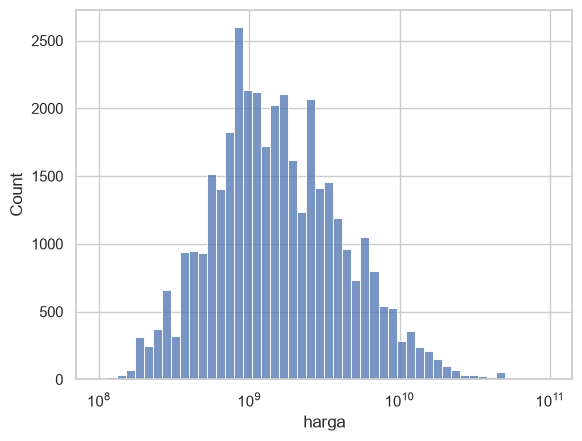

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df_final["harga"], log_scale=True, bins=50)
plt.show()

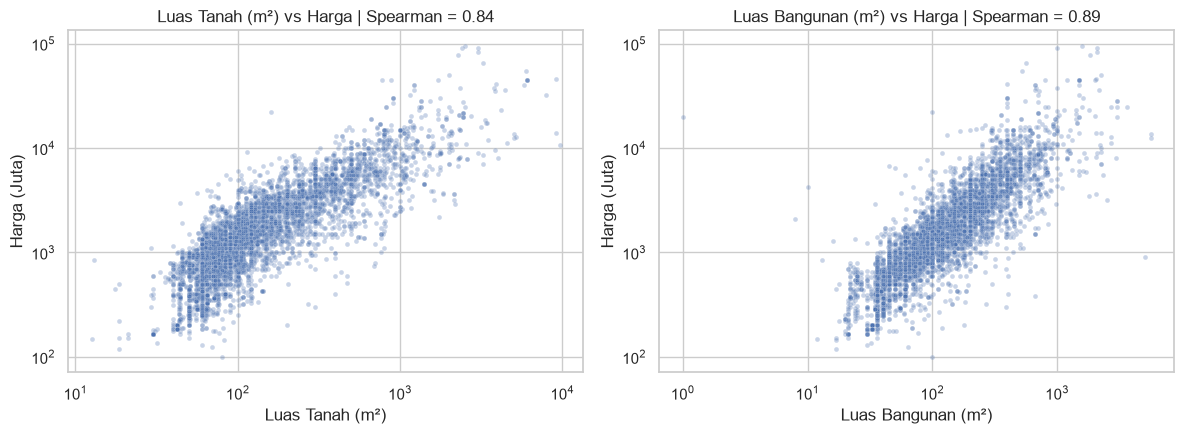

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

SEED = 42

eda = df_final.copy()
eda["harga_juta"] = eda["harga"] / 1e6

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
s = eda.sample(min(6000, len(eda)), random_state=SEED)

for a, kol, nama in zip(
    ax, ["luas_tanah", "luas_bangunan"], ["Luas Tanah (m²)", "Luas Bangunan (m²)"]
):
    sns.scatterplot(data=s, x=kol, y="harga_juta", alpha=0.3, s=12, ax=a)
    a.set_xscale("log")
    a.set_yscale("log")
    a.set_xlabel(nama)
    a.set_ylabel("Harga (Juta)")
    rho = spearmanr(eda[kol], eda["harga_juta"], nan_policy="omit")[0]
    a.set_title(f"{nama} vs Harga | Spearman = {rho:.2f}")

plt.tight_layout()
plt.show()

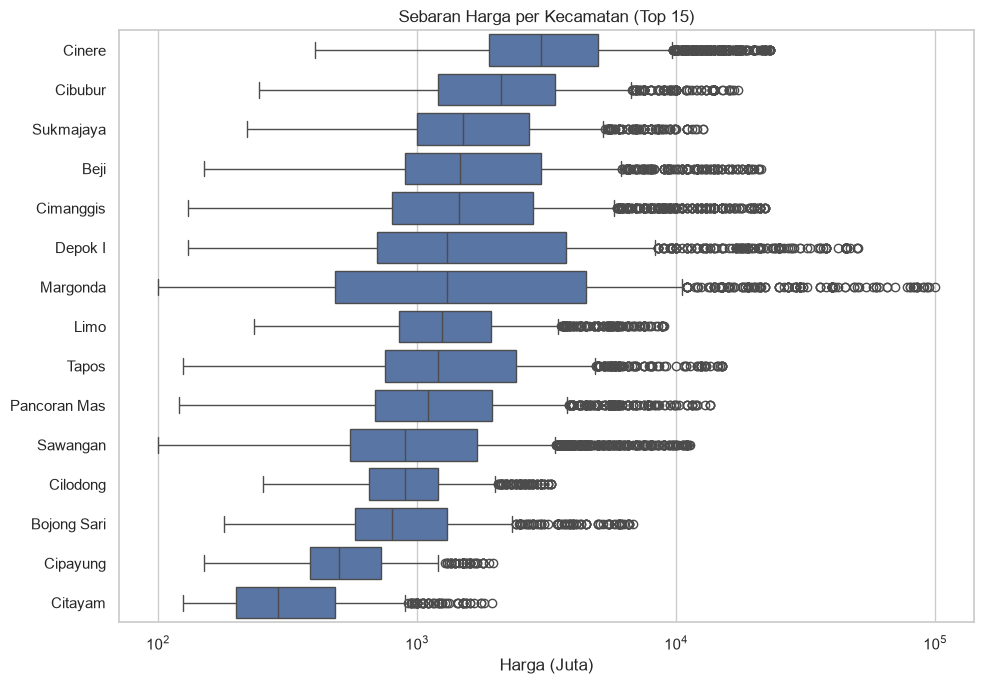

In [53]:
top = eda["kecamatan"].value_counts().head(15).index
d = eda[eda["kecamatan"].isin(top)]
urut = d.groupby("kecamatan")["harga_juta"].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 7))
sns.boxplot(data=d, x="harga_juta", y="kecamatan", order=urut)
plt.xscale("log")
plt.xlabel("Harga (Juta)")
plt.ylabel("")
plt.title("Sebaran Harga per Kecamatan (Top 15)")
plt.tight_layout()
plt.show()

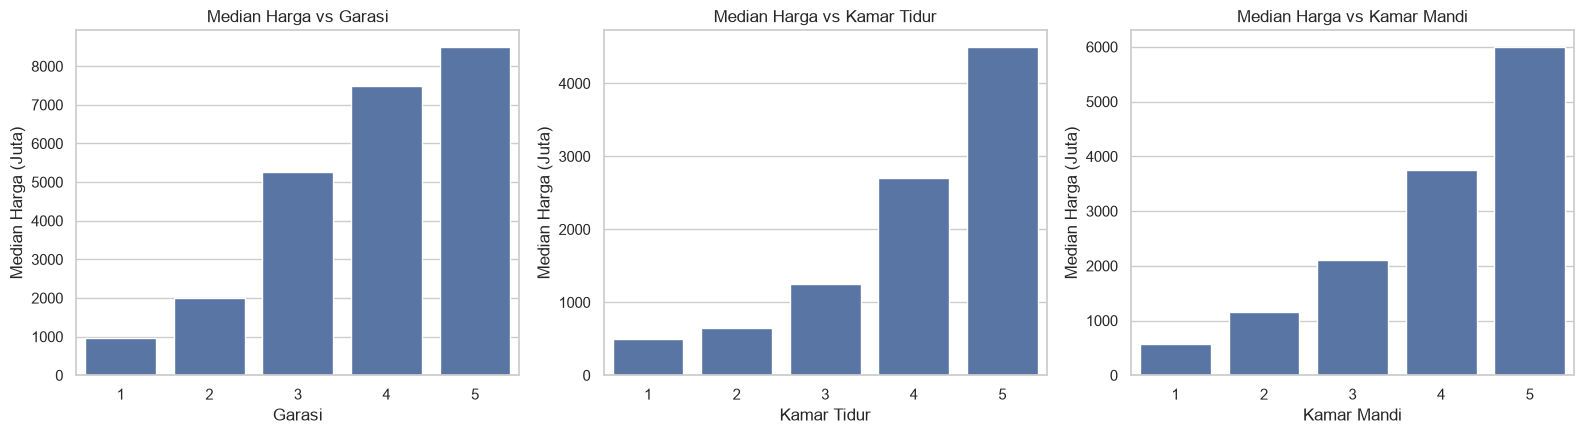

In [54]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

for a, kol, nama in zip(
    ax,
    ["garasi", "kamar_tidur", "kamar_mandi"],
    ["Garasi", "Kamar Tidur", "Kamar Mandi"],
):
    n = eda[kol].value_counts()
    d = eda[eda[kol].isin(n[n >= 30].index)]  # buang nilai yang datanya terlalu sedikit
    med = d.groupby(kol)["harga_juta"].median()
    sns.barplot(x=med.index.astype(int), y=med.values, ax=a)
    a.set_xlabel(nama)
    a.set_ylabel("Median Harga (Juta)")
    a.set_title(f"Median Harga vs {nama}")

plt.tight_layout()
plt.show()

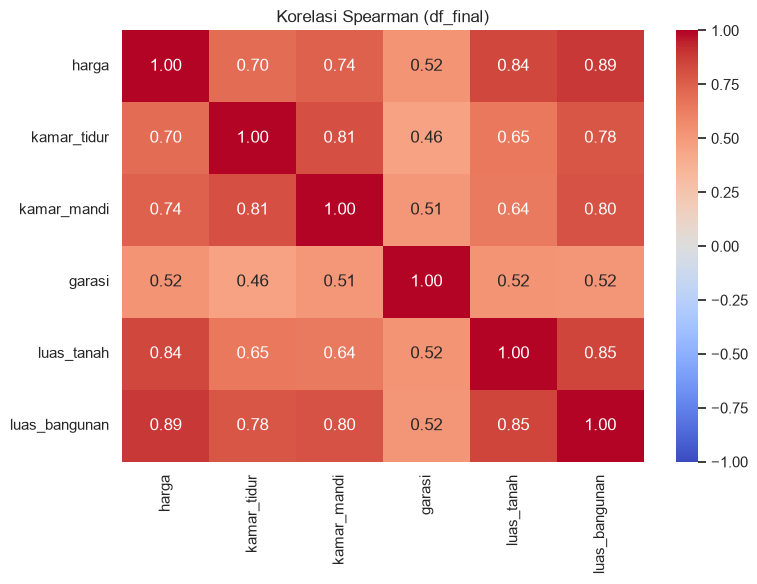

In [55]:
kolom = ["harga", "kamar_tidur", "kamar_mandi", "garasi", "luas_tanah", "luas_bangunan"]

corr = df_final[kolom].astype(float).corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi Spearman (df_final)")
plt.tight_layout()
plt.show()

# 2. Direct Modelling

## Pemilihan Model Baseline (Sebelum Preprocessing)

Dataset berisi ±40 ribu listing rumah dengan fitur numerik dan kategorikal (`Kecamatan`), banyak nilai kosong, dan outlier harga ekstrem. Enam model dipilih dari pendekatan yang berbeda sebagai kontrol untuk mengukur efektivitas preprocessing.

- **Ridge Regression:** baseline linear, penalti L2 menjaga koefisien stabil karena `luas_tanah` dan `luas_bangunan` saling berkorelasi.
- **KNN Regressor:** memprediksi harga dari rumah yang mirip, tapi sensitif terhadap skala dan outlier sehingga cocok untuk melihat dampak preprocessing.
- **Random Forest (bagging):** menangkap hubungan non-linear, tahan outlier, tanpa scaling.
- **XGBoost (boosting):** kuat di data tabular dan punya regularisasi bawaan.
- **LightGBM (boosting):** efisien untuk puluhan ribu baris dan bisa menangani nilai kosong.
- **CatBoost (boosting):** menangani `Kecamatan` secara native tanpa one-hot encoding.

Kombinasi model linear, berbasis jarak, dan ensemble membuat kita bisa melihat apakah preprocessing memperbaiki kualitas data (Ridge dan KNN naik) atau menambah informasi bagi model pohon.

In [56]:
raw = pd.read_csv(DATA_PATH, index_col=False)

e = raw["Harga"].str.extract(r"([\d,\.]+)\s*(Ribu|Juta|Miliar|Triliun)")
raw["harga"] = e[0].str.replace(",", ".").astype(float) * e[1].map(
    {"Ribu": 1e3, "Juta": 1e6, "Miliar": 1e9, "Triliun": 1e12}
)
raw = raw.dropna(subset=["harga"])

for c in ["Kamar Tidur", "Kamar Mandi", "Garasi"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
for c in ["Luas Tanah", "Luas Bangunan"]:
    raw[c] = raw[c].astype(str).str.extract(r"(\d+)")[0].astype(float)

num_r = ["Kamar Tidur", "Kamar Mandi", "Garasi", "Luas Tanah", "Luas Bangunan"]
yr = raw["harga"]
Xr_oh = pd.get_dummies(raw[num_r + ["Kecamatan"]], columns=["Kecamatan"], dtype=float)
Xr_cb = raw[num_r + ["Kecamatan"]]
tr, te = train_test_split(raw.index, test_size=0.2, random_state=42)


def evaluasi_raw(nama, model, X):
    model.fit(X.loc[tr], yr.loc[tr])
    p, yt = model.predict(X.loc[te]), yr.loc[te]
    return [
        nama,
        np.sqrt(mean_squared_error(yt, p)),
        mean_absolute_error(yt, p),
        r2_score(yt, p),
        np.mean(np.abs((yt - p) / yt)) * 100,
    ]


from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

hasil_raw = [
    evaluasi_raw(
        "Ridge", make_pipeline(SimpleImputer(strategy="median"), Ridge()), Xr_oh
    ),
    evaluasi_raw(
        "KNN",
        make_pipeline(SimpleImputer(strategy="median"), KNeighborsRegressor()),
        Xr_oh,
    ),
    evaluasi_raw(
        "RandomForest", RandomForestRegressor(n_jobs=-1, random_state=42), Xr_oh
    ),
    evaluasi_raw("XGBoost", XGBRegressor(random_state=42), Xr_oh),
    evaluasi_raw("LightGBM", LGBMRegressor(random_state=42, verbose=-1), Xr_oh),
    evaluasi_raw(
        "CatBoost",
        CatBoostRegressor(random_state=42, verbose=0, cat_features=["Kecamatan"]),
        Xr_cb,
    ),
]

pd.DataFrame(hasil_raw, columns=["model", "RMSE", "MAE", "R2", "MAPE_%"]).sort_values(
    "RMSE"
)

,model,RMSE,MAE,R2,MAPE_%
1,KNN,6.925846e+12,1.480672e+11,-0.004462,5622.038996
5,CatBoost,6.976374e+12,3.270821e+11,-0.019172,164918.237024
2,RandomForest,7.119847e+12,2.965020e+11,-0.061523,169924.851520
3,XGBoost,7.173517e+12,3.090662e+11,-0.077587,177243.625477
4,LightGBM,7.173714e+12,3.106674e+11,-0.077646,178497.266202
0,Ridge,6.202671e+13,1.022695e+12,-79.564834,181171.881769


# 3. Modelling dengan Preprocess

In [57]:
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

num = ["kamar_tidur", "kamar_mandi", "garasi", "luas_tanah", "luas_bangunan"]
y = df_final["harga"]

X_oh = pd.get_dummies(df_final[num + ["kecamatan"]], columns=["kecamatan"], dtype=float)
X_cb = df_final[num + ["kecamatan"]]

idx_tr, idx_te = train_test_split(df_final.index, test_size=0.2, random_state=42)


def evaluasi(nama, model, X):
    model.fit(X.loc[idx_tr], y.loc[idx_tr])
    p = model.predict(X.loc[idx_te])
    yt = y.loc[idx_te]
    return [
        nama,
        np.sqrt(mean_squared_error(yt, p)),
        mean_absolute_error(yt, p),
        r2_score(yt, p),
        np.mean(np.abs((yt - p) / yt)) * 100,
    ]


hasil = [
    evaluasi("Ridge", Ridge(), X_oh),
    evaluasi("KNN", KNeighborsRegressor(), X_oh),
    evaluasi("RandomForest", RandomForestRegressor(n_jobs=-1, random_state=42), X_oh),
    evaluasi("XGBoost", XGBRegressor(random_state=42), X_oh),
    evaluasi("LightGBM", LGBMRegressor(random_state=42, verbose=-1), X_oh),
    evaluasi(
        "CatBoost",
        CatBoostRegressor(random_state=42, verbose=0, cat_features=["kecamatan"]),
        X_cb,
    ),
]

pd.DataFrame(hasil, columns=["model", "RMSE", "MAE", "R2", "MAPE_%"]).sort_values(
    "RMSE"
)

,model,RMSE,MAE,R2,MAPE_%
2,RandomForest,1.610766e+09,5.295644e+08,0.873363,21.865478
5,CatBoost,1.705337e+09,7.046801e+08,0.858057,31.628692
4,LightGBM,1.791370e+09,7.294252e+08,0.843374,33.400885
3,XGBoost,1.825812e+09,6.680725e+08,0.837293,29.641300
1,KNN,2.738161e+09,7.446693e+08,0.634058,28.220156
0,Ridge,3.211859e+09,1.359461e+09,0.496491,86.031671


# 4. Feature Selection

In [58]:
from sklearn.compose import make_column_transformer
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

fitur = [
    "kamar_tidur",
    "kamar_mandi",
    "garasi",
    "luas_tanah",
    "luas_bangunan",
    "kecamatan",
]
X = df_final[fitur]
y = df_final["harga"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

pipe = make_pipeline(
    make_column_transformer(
        (OneHotEncoder(handle_unknown="ignore"), ["kecamatan"]), remainder="passthrough"
    ),
    RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42),
).fit(X_tr, y_tr)

pi = permutation_importance(
    pipe,
    X_te,
    y_te,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)
print(pd.Series(pi.importances_mean, index=fitur).sort_values(ascending=False))

luas_tanah       1.305351e+09
luas_bangunan    8.726086e+08
kecamatan        4.497524e+08
kamar_mandi      1.424877e+08
kamar_tidur      8.780190e+07
garasi           4.381232e+07
dtype: float64


Tanpa garasi karena fitur paling lemah

In [ ]:
num2 = ["kamar_tidur", "kamar_mandi", "luas_tanah", "luas_bangunan"]

X2_oh = pd.get_dummies(
    df_final[num2 + ["kecamatan"]], columns=["kecamatan"], dtype=float
)
X2_cb = df_final[num2 + ["kecamatan"]]

hasil2 = [
    evaluasi("Ridge", Ridge(), X2_oh),
    evaluasi("KNN", KNeighborsRegressor(), X2_oh),
    evaluasi("RandomForest", RandomForestRegressor(n_jobs=-1, random_state=42), X2_oh),
    evaluasi("XGBoost", XGBRegressor(random_state=42), X2_oh),
    evaluasi("LightGBM", LGBMRegressor(random_state=42, verbose=-1), X2_oh),
    evaluasi(
        "CatBoost",
        CatBoostRegressor(random_state=42, verbose=0, cat_features=["kecamatan"]),
        X2_cb,
    ),
]

pd.DataFrame(hasil2, columns=["model", "RMSE", "MAE", "R2", "MAPE_%"]).sort_values(
    "RMSE"
)

,model,RMSE,MAE,R2,MAPE_%
2,RandomForest,1.584222e+09,5.217626e+08,0.877503,21.725378
5,CatBoost,1.759082e+09,7.090717e+08,0.848969,31.813511
3,XGBoost,1.789223e+09,6.602719e+08,0.843749,29.059845
4,LightGBM,1.812760e+09,7.336181e+08,0.839611,33.445667
1,KNN,2.737368e+09,7.454052e+08,0.634270,28.329146
0,Ridge,3.277124e+09,1.359966e+09,0.475821,84.558138


# 5. Hyperparameter Tuning

In [62]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import RandomizedSearchCV


def log_wrap(m):
    return TransformedTargetRegressor(regressor=m, func=np.log1p, inverse_func=np.expm1)


kandidat = {
    "RandomForest": (
        RandomForestRegressor(n_jobs=-1, random_state=42),
        {
            "regressor__n_estimators": [300, 500, 800],
            "regressor__max_depth": [None, 20, 30],
            "regressor__min_samples_leaf": [1, 2, 3],
            "regressor__max_features": [0.5, 0.7, 1.0],
        },
    ),
    "XGBoost": (
        XGBRegressor(random_state=42, n_jobs=-1),
        {
            "regressor__n_estimators": [400, 800, 1200],
            "regressor__learning_rate": [0.02, 0.05, 0.1],
            "regressor__max_depth": [4, 6, 8, 10],
            "regressor__subsample": [0.7, 0.85, 1.0],
            "regressor__colsample_bytree": [0.6, 0.8, 1.0],
            "regressor__min_child_weight": [1, 3, 5],
        },
    ),
    "LightGBM": (
        LGBMRegressor(random_state=42, verbose=-1, n_jobs=-1),
        {
            "regressor__n_estimators": [400, 800, 1200],
            "regressor__learning_rate": [0.02, 0.05, 0.1],
            "regressor__num_leaves": [31, 63, 127, 255],
            "regressor__min_child_samples": [5, 10, 20],
            "regressor__subsample": [0.7, 0.85, 1.0],
            "regressor__colsample_bytree": [0.6, 0.8, 1.0],
        },
    ),
    "CatBoost": (
        CatBoostRegressor(random_state=42, verbose=0, thread_count=-1),
        {
            "regressor__iterations": [500, 1000],
            "regressor__depth": [6, 8, 10],
            "regressor__learning_rate": [0.03, 0.05, 0.1],
            "regressor__l2_leaf_reg": [1, 3, 5, 9],
        },
    ),
}

hasil_tuning, terbaik = [], {}
for nama, (model, param) in kandidat.items():
    cari = RandomizedSearchCV(
        log_wrap(model),
        param,
        n_iter=20,
        cv=3,
        scoring="neg_mean_absolute_error",
        random_state=42,
        n_jobs=1 if nama in ("RandomForest",) else -1,
    )
    cari.fit(X2_oh.loc[idx_tr], y.loc[idx_tr])  # CV hanya di data train
    terbaik[nama] = cari.best_estimator_
    print(nama, cari.best_params_)
    hasil_tuning.append(
        evaluasi(f"{nama}_tuned", cari.best_estimator_, X2_oh)
    )  # test set dipakai sekali di sini

tabel = pd.DataFrame(
    hasil_tuning, columns=["model", "RMSE", "MAE", "R2", "MAPE_%"]
).sort_values("MAE")
tabel

RandomForest {'regressor__n_estimators': 500, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 0.7, 'regressor__max_depth': None}
XGBoost {'regressor__subsample': 0.85, 'regressor__n_estimators': 1200, 'regressor__min_child_weight': 1, 'regressor__max_depth': 8, 'regressor__learning_rate': 0.1, 'regressor__colsample_bytree': 0.6}
LightGBM {'regressor__subsample': 1.0, 'regressor__num_leaves': 255, 'regressor__n_estimators': 400, 'regressor__min_child_samples': 5, 'regressor__learning_rate': 0.05, 'regressor__colsample_bytree': 1.0}
CatBoost {'regressor__learning_rate': 0.1, 'regressor__l2_leaf_reg': 1, 'regressor__iterations': 1000, 'regressor__depth': 10}


,model,RMSE,MAE,R2,MAPE_%
0,RandomForest_tuned,1.570310e+09,5.100003e+08,0.879645,19.705503
2,LightGBM_tuned,1.707096e+09,5.533683e+08,0.857764,20.997821
1,XGBoost_tuned,1.870544e+09,5.754939e+08,0.829223,21.351329
3,CatBoost_tuned,1.656554e+09,5.855266e+08,0.866062,22.344128


In [ ]:
import json
import os
from datetime import datetime

import joblib
import numpy as np

os.makedirs("model", exist_ok=True)

p = terbaik["RandomForest"].regressor_.get_params()
rf_kecil = log_wrap(
    RandomForestRegressor(
        n_estimators=200,
        max_depth=p["max_depth"],
        min_samples_leaf=max(p["min_samples_leaf"], 3),
        max_features=p["max_features"],
        n_jobs=-1,
        random_state=42,
    )
)

rf_kecil.fit(X2_oh.loc[idx_tr], y.loc[idx_tr])
pred = rf_kecil.predict(X2_oh.loc[idx_te])
yt = y.loc[idx_te]

joblib.dump(rf_kecil, "model/model_rf.joblib", compress=3)
joblib.dump(list(X2_oh.columns), "model/kolom.joblib", compress=3)
ukuran = os.path.getsize("model/model_rf.joblib") / 1e6

meta = {
    "model": "RandomForest kecil (target log1p, n_estimators=200, min_samples_leaf>=3)",
    "fitur": num2 + ["kecamatan"],
    "target": "harga (Rupiah)",
    "metrik_test": {
        "RMSE": float(np.sqrt(mean_squared_error(yt, pred))),
        "MAE": float(mean_absolute_error(yt, pred)),
        "R2": float(r2_score(yt, pred)),
        "MAPE_%": float(np.mean(np.abs((yt - pred) / yt)) * 100),
    },
    "ukuran_mb": round(ukuran, 1),
    "dibuat": datetime.now().isoformat(timespec="seconds"),
}
with open("model/meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print(f"{ukuran:.1f} MB")
print(json.dumps(meta["metrik_test"], indent=2))

# 6. Export Clean Data

In [67]:
d = df_final.copy()
d["harga_juta"] = d["harga"] / 1e6
d.to_csv("data_bersih.csv", index=False)